# 豆瓣电影评论情感分析


## 1. 导入依赖 & 加载数据


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import warnings
warnings.filterwarnings('ignore')
from snownlp import SnowNLP
import jieba
from collections import Counter
from wordcloud import WordCloud
import os

# 中文字体
matplotlib.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'Heiti SC', 'SimHei']
matplotlib.rcParams['axes.unicode_minus'] = False

# 学号后两位/后一位（按要求修改）
STUDENT_ID_LAST2 = 73
STUDENT_ID_LAST1 = STUDENT_ID_LAST2 % 10

# 随机种子（学号后两位）
RANDOM_SEED = STUDENT_ID_LAST2
np.random.seed(RANDOM_SEED)
print(f'随机种子: {RANDOM_SEED}, 学号末位: {STUDENT_ID_LAST1}')

# 输出目录
os.makedirs('output', exist_ok=True)

# 停用词（可自行扩充）
STOPWORDS = {
    '的','了','是','我','你','他','她','们','这','那','就','都','也','还','有','在','不','和','很','太',
    '真','好','看','电影','一个','什么','没有','可以','觉得','感觉','非常','比较','一部','这部'
}


随机种子: 73, 学号末位: 3


In [2]:
# 加载数据
df = pd.read_csv('data/comments.csv')
print(f'加载 {len(df)} 条评论')
df.head()


加载 75 条评论


,movie_id,movie_title,content,rating,votes
0,1292052,肖申克的救赎,恐惧让你沦为囚犯，希望让你重获自由。——《肖申克的救赎》,5,25451
1,1292052,肖申克的救赎,当年的奥斯卡颁奖礼上，被如日中天的《阿甘正传》掩盖了它的光彩，而随着时间的推移，这部电影在越...,5,22899
2,1292052,肖申克的救赎,策划了19年的私奔……,5,18447
3,1292052,肖申克的救赎,关于希望最强有力的注释。,5,13944
4,1292052,肖申克的救赎,“这是一部男人必看的电影。”人人都这么说。但单纯从性别区分，就会让这电影变狭隘。《肖申克的救...,5,12628


## 2. 数据清洗


In [3]:
print('数据清洗前:', len(df))

# 去除空评论
df = df.dropna(subset=['content'])
df = df[df['content'].str.strip() != '']

# 去重
df = df.drop_duplicates(subset=['content'])

# 只保留有评分的数据（用于好/中/差评标签）
df = df[df['rating'].notna()]
df = df[df['rating'] > 0]

# 评分映射为好/中/差

def rating_to_label(rating):
    if rating >= 4:
        return '好评'
    if rating == 3:
        return '中评'
    return '差评'


df['rating_label'] = df['rating'].apply(rating_to_label)

print('数据清洗后:', len(df))
print()
print('各电影评论数:')
print(df['movie_title'].value_counts())
print()
print('评分分布:')
print(df['rating'].value_counts().sort_index())
print()
print('好/中/差分布:')
print(df['rating_label'].value_counts())


数据清洗前: 75
数据清洗后: 75

各电影评论数:
movie_title
肖申克的救赎     15
霸王别姬       15
这个杀手不太冷    15
阿甘正传       15
美丽人生       15
Name: count, dtype: int64

评分分布:
rating
3     1
4    13
5    61
Name: count, dtype: int64

好/中/差分布:
rating_label
好评    74
中评     1
Name: count, dtype: int64


## 3. SnowNLP 情感分析


In [4]:
# 情感分析
df['snownlp_score'] = df['content'].apply(lambda x: SnowNLP(str(x)).sentiments)
df['snownlp_label'] = df['snownlp_score'].apply(
    lambda x: '好评' if x > 0.6 else ('差评' if x < 0.4 else '中评')
)

print('='*50)
print('SnowNLP 情感分析结果')
print('='*50)
print()
print('情感分布:')
print(df['snownlp_label'].value_counts())
print()
print('情感得分统计:')
print(f'  均值: {df["snownlp_score"].mean():.4f}')
print(f'  中位数: {df["snownlp_score"].median():.4f}')
print(f'  标准差: {df["snownlp_score"].std():.4f}')


SnowNLP 情感分析结果

情感分布:
snownlp_label
好评    61
差评    10
中评     4
Name: count, dtype: int64

情感得分统计:
  均值: 0.8275
  中位数: 0.9924
  标准差: 0.2823


## 4. 机器学习情感分析


In [5]:
# 准备标签（使用评分映射的好/中/差作为真实标签）
label_map = {'差评': 0, '中评': 1, '好评': 2}
df['ml_label'] = df['rating_label'].map(label_map)

# 特征提取

def extract_features(texts, top_k=500):
    all_words, docs_words = [], []
    for text in texts:
        words = [w for w in jieba.cut(str(text)) if len(w) > 1 and w not in STOPWORDS]
        docs_words.append(words)
        all_words.extend(words)
    vocab = [w for w, _ in Counter(all_words).most_common(top_k)]
    word_to_idx = {w: i for i, w in enumerate(vocab)}
    features = np.zeros((len(texts), len(vocab)))
    for i, words in enumerate(docs_words):
        for w in words:
            idx = word_to_idx.get(w)
            if idx is not None:
                features[i, idx] += 1
    return features, vocab, word_to_idx


def texts_to_features(texts, word_to_idx):
    features = np.zeros((len(texts), len(word_to_idx)))
    for i, text in enumerate(texts):
        words = [w for w in jieba.cut(str(text)) if len(w) > 1 and w not in STOPWORDS]
        for w in words:
            idx = word_to_idx.get(w)
            if idx is not None:
                features[i, idx] += 1
    return features


X, vocab, word_to_idx = extract_features(df['content'].values)
y = df['ml_label'].values
print(f'特征维度: {X.shape}')


Building prefix dict from the default dictionary ...


Loading model from cache /var/folders/n6/g2_951ps3gg2gc9fqq62ljl80000gn/T/jieba.cache


Loading model cost 0.256 seconds.


Prefix dict has been built successfully.


特征维度: (75, 500)


In [6]:
# 划分数据集
n = len(X)
indices = np.random.permutation(n)
train_size = int(n * 0.8)
X_train, X_test = X[indices[:train_size]], X[indices[train_size:]]
y_train, y_test = y[indices[:train_size]], y[indices[train_size:]]
print(f'训练集: {len(X_train)}, 测试集: {len(X_test)}')


训练集: 60, 测试集: 15


In [7]:
# 朴素贝叶斯

def train_naive_bayes(X_train, y_train):
    classes = np.unique(y_train)
    n_features = X_train.shape[1]
    priors = np.array([np.sum(y_train == c) / len(y_train) for c in classes])
    likelihoods = np.zeros((len(classes), n_features))
    for i, c in enumerate(classes):
        X_c = X_train[y_train == c]
        likelihoods[i] = (X_c.sum(axis=0) + 1) / (X_c.sum() + n_features)
    return {'classes': classes, 'priors': priors, 'likelihoods': likelihoods}


def predict_naive_bayes(model, X):
    classes = model['classes']
    priors = model['priors']
    likelihoods = model['likelihoods']
    preds = []
    for x in X:
        posts = [np.log(priors[i]) + np.sum(x * np.log(likelihoods[i] + 1e-10)) for i in range(len(classes))]
        preds.append(classes[np.argmax(posts)])
    return np.array(preds)


# 逻辑回归

def train_logistic_regression(X_train, y_train, lr=0.01, epochs=100):
    classes = np.unique(y_train)
    n_features = X_train.shape[1]
    weights = np.zeros((len(classes), n_features))
    biases = np.zeros(len(classes))
    sigmoid = lambda z: 1 / (1 + np.exp(-np.clip(z, -500, 500)))
    for i, c in enumerate(classes):
        y_bin = (y_train == c).astype(int)
        w, b = np.zeros(n_features), 0
        for _ in range(epochs):
            pred = sigmoid(X_train @ w + b)
            w -= lr * (X_train.T @ (pred - y_bin)) / len(y_train)
            b -= lr * np.mean(pred - y_bin)
        weights[i], biases[i] = w, b
    return {'classes': classes, 'weights': weights, 'biases': biases}


def predict_logistic_regression(model, X):
    classes = model['classes']
    weights = model['weights']
    biases = model['biases']
    return classes[np.argmax(X @ weights.T + biases, axis=1)]


In [8]:
# 评估函数

def evaluate(y_true, y_pred):
    classes = np.unique(y_true)
    acc = np.mean(y_true == y_pred)
    precs, recs, f1s = [], [], []
    for c in classes:
        tp = np.sum((y_pred == c) & (y_true == c))
        fp = np.sum((y_pred == c) & (y_true != c))
        fn = np.sum((y_pred != c) & (y_true == c))
        p = tp / (tp + fp) if (tp + fp) > 0 else 0
        r = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2*p*r / (p+r) if (p+r) > 0 else 0
        precs.append(p)
        recs.append(r)
        f1s.append(f1)
    return {'accuracy': acc, 'precision': np.mean(precs), 'recall': np.mean(recs), 'f1': np.mean(f1s)}


In [9]:
# 训练和评估
print('训练模型...')
nb_model = train_naive_bayes(X_train, y_train)
lr_model = train_logistic_regression(X_train, y_train, lr=0.01, epochs=100)

nb_pred = predict_naive_bayes(nb_model, X_test)
lr_pred = predict_logistic_regression(lr_model, X_test)
nb_res = evaluate(y_test, nb_pred)
lr_res = evaluate(y_test, lr_pred)

print()
print('='*50)
print(f'模型对比 (随机种子: {RANDOM_SEED})')
print('='*50)
print(f"{'指标':<10} {'朴素贝叶斯':<12} {'逻辑回归':<12}")
print('-'*34)
print(f"{'准确率':<10} {nb_res['accuracy']:<12.2%} {lr_res['accuracy']:<12.2%}")
print(f"{'精确率':<10} {nb_res['precision']:<12.2%} {lr_res['precision']:<12.2%}")
print(f"{'召回率':<10} {nb_res['recall']:<12.2%} {lr_res['recall']:<12.2%}")
print(f"{'F1分数':<10} {nb_res['f1']:<12.2%} {lr_res['f1']:<12.2%}")


训练模型...

模型对比 (随机种子: 73)
指标         朴素贝叶斯        逻辑回归        
----------------------------------
准确率        73.33%       100.00%     
精确率        100.00%      100.00%     
召回率        73.33%       100.00%     
F1分数       84.62%       100.00%     


In [10]:
# 样本对比（n=学号末位）
sample_n = STUDENT_ID_LAST1
sample_idx = sample_n - 1 if sample_n > 0 else 0
if sample_idx >= len(df):
    sample_idx = sample_idx % len(df)

sample_row = df.iloc[sample_idx]
sample_text = sample_row['content']
sample_true_label = sample_row['rating_label']

sample_score = SnowNLP(str(sample_text)).sentiments
sample_snownlp_label = '好评' if sample_score > 0.6 else ('差评' if sample_score < 0.4 else '中评')

sample_features = texts_to_features([sample_text], word_to_idx)
sample_nb = predict_naive_bayes(nb_model, sample_features)[0]
sample_lr = predict_logistic_regression(lr_model, sample_features)[0]
inv_label_map = {v: k for k, v in label_map.items()}

print('='*50)
print(f'样本对比 (n=学号末位={sample_n}, 行号={sample_idx+1})')
print('='*50)
print(f'评论: {sample_text}')
print(f'真实标签(评分): {sample_true_label} (评分={sample_row["rating"]})')
print(f'SnowNLP 得分: {sample_score:.4f} -> {sample_snownlp_label}')
print(f'朴素贝叶斯预测: {inv_label_map[sample_nb]}')
print(f'逻辑回归预测: {inv_label_map[sample_lr]}')


样本对比 (n=学号末位=3, 行号=3)
评论: 策划了19年的私奔……
真实标签(评分): 好评 (评分=5)
SnowNLP 得分: 0.9793 -> 好评
朴素贝叶斯预测: 好评
逻辑回归预测: 好评


## 5. 可视化


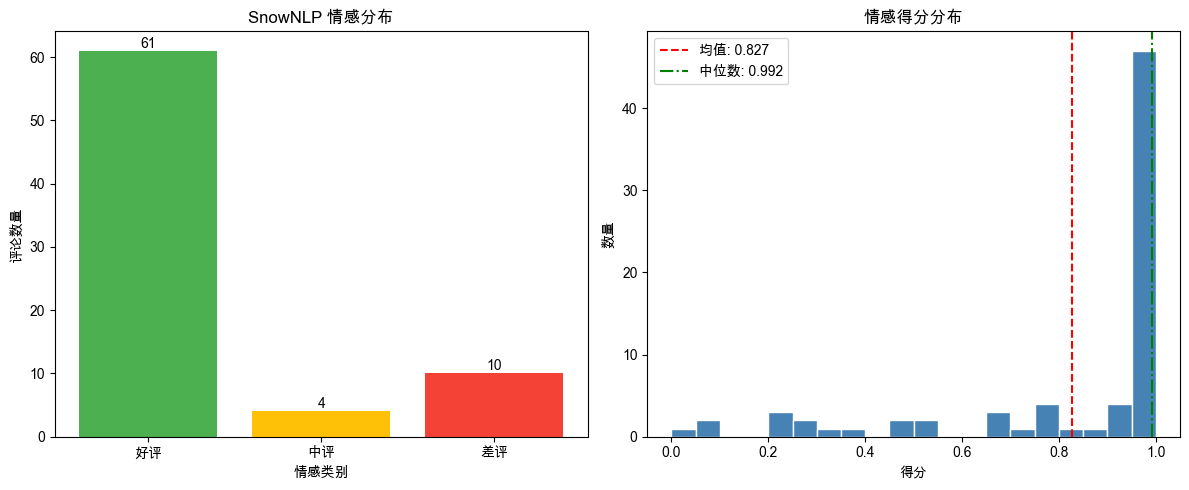

In [11]:
# 情感分布图
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 柱形图
colors = {'好评': '#4CAF50', '中评': '#FFC107', '差评': '#F44336'}
order = ['好评', '中评', '差评']
counts = df['snownlp_label'].value_counts().reindex(order, fill_value=0)
bars = axes[0].bar(counts.index, counts.values, color=[colors[x] for x in counts.index])
axes[0].set_title('SnowNLP 情感分布')
axes[0].set_xlabel('情感类别')
axes[0].set_ylabel('评论数量')
for bar, v in zip(bars, counts.values):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5, str(v), ha='center')

# 直方图
axes[1].hist(df['snownlp_score'], bins=20, color='steelblue', edgecolor='white')
axes[1].axvline(df['snownlp_score'].mean(), color='red', linestyle='--', label=f"均值: {df['snownlp_score'].mean():.3f}")
axes[1].axvline(df['snownlp_score'].median(), color='green', linestyle='-.', label=f"中位数: {df['snownlp_score'].median():.3f}")
axes[1].set_title('情感得分分布')
axes[1].set_xlabel('得分')
axes[1].set_ylabel('数量')
axes[1].legend()
plt.tight_layout()
plt.savefig('output/sentiment_distribution.png', dpi=150)
plt.show()


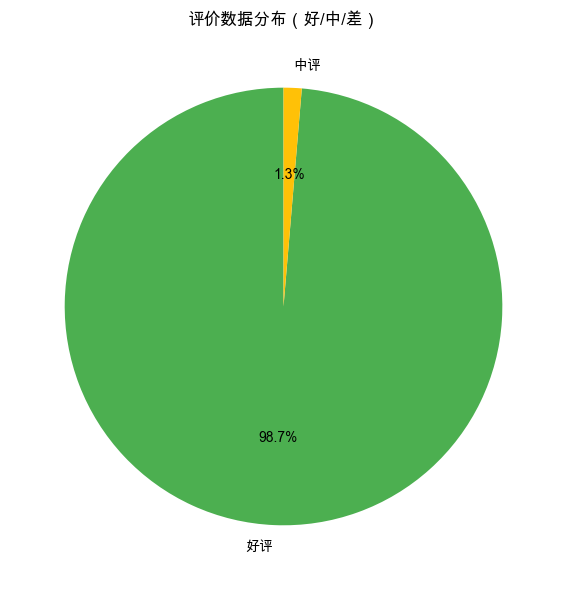

In [12]:
# 评价数据分布饼图（好/中/差）
plt.figure(figsize=(6, 6))
counts = df['rating_label'].value_counts()
colors = {'好评': '#4CAF50', '中评': '#FFC107', '差评': '#F44336'}
plt.pie(
    counts.values,
    labels=counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=[colors.get(x, '#999999') for x in counts.index]
)
plt.title('评价数据分布（好/中/差）')
plt.tight_layout()
plt.savefig('output/rating_distribution_pie.png', dpi=150)
plt.show()


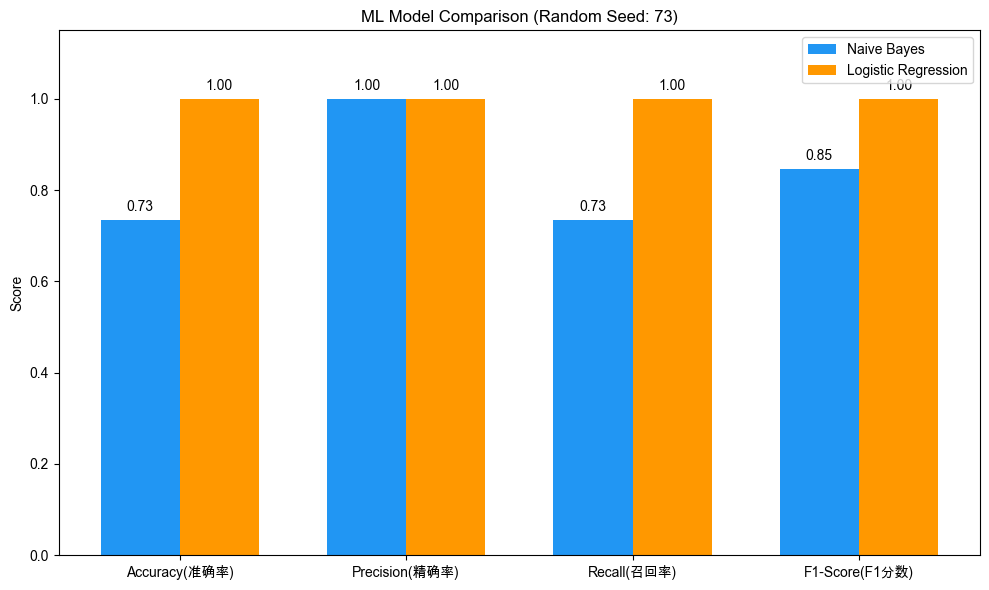

In [13]:
# 模型对比图
fig, ax = plt.subplots(figsize=(10, 6))
metrics = ['accuracy', 'precision', 'recall', 'f1']
names = ['Accuracy(准确率)', 'Precision(精确率)', 'Recall(召回率)', 'F1-Score(F1分数)']
x = np.arange(len(metrics))
width = 0.35
bars1 = ax.bar(x - width/2, [nb_res[m] for m in metrics], width, label='Naive Bayes', color='#2196F3')
bars2 = ax.bar(x + width/2, [lr_res[m] for m in metrics], width, label='Logistic Regression', color='#FF9800')
ax.set_ylabel('Score')
ax.set_title(f'ML Model Comparison (Random Seed: {RANDOM_SEED})')
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.legend()
ax.set_ylim(0, 1.15)
for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02, f'{bar.get_height():.2f}', ha='center')
plt.tight_layout()
plt.savefig('output/model_comparison.png', dpi=150)
plt.show()


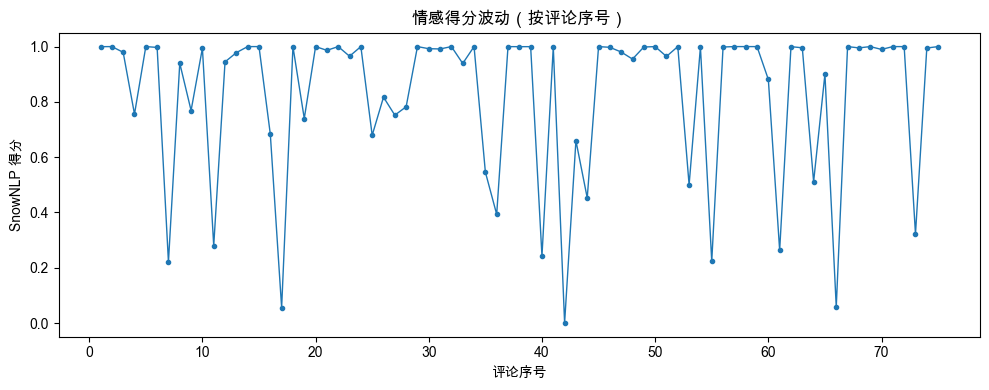

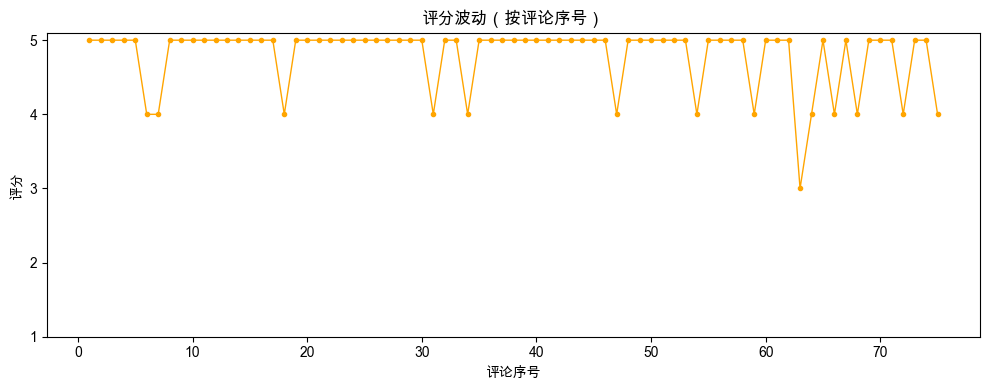

未检测到 comment_time 字段，跳过时间趋势图（如需，请重新爬取数据）。


In [14]:
# 情况分析波动图
# 情感得分随评论序号波动
plt.figure(figsize=(10, 4))
idx = np.arange(1, len(df) + 1)
plt.plot(idx, df['snownlp_score'].values, marker='o', markersize=3, linewidth=1)
plt.title('情感得分波动（按评论序号）')
plt.xlabel('评论序号')
plt.ylabel('SnowNLP 得分')
plt.tight_layout()
plt.savefig('output/sentiment_score_trend.png', dpi=150)
plt.show()

# 评分随评论序号波动
plt.figure(figsize=(10, 4))
plt.plot(idx, df['rating'].values, marker='o', markersize=3, linewidth=1, color='orange')
plt.title('评分波动（按评论序号）')
plt.xlabel('评论序号')
plt.ylabel('评分')
plt.yticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.savefig('output/rating_trend.png', dpi=150)
plt.show()

# 按时间趋势（需要 comment_time 字段）
if 'comment_time' in df.columns:
    time_df = df[['comment_time', 'snownlp_score']].copy()
    time_df['comment_time'] = pd.to_datetime(time_df['comment_time'], errors='coerce')
    time_df = time_df.dropna(subset=['comment_time']).sort_values('comment_time')
    if len(time_df) > 1:
        plt.figure(figsize=(10, 4))
        plt.plot(time_df['comment_time'], time_df['snownlp_score'], alpha=0.4, label='原始得分')
        window = min(5, len(time_df))
        trend = time_df['snownlp_score'].rolling(window=window, min_periods=1).mean()
        plt.plot(time_df['comment_time'], trend, color='red', linewidth=2, label=f'滚动均值(window={window})')
        plt.title('情感得分趋势（按时间）')
        plt.xlabel('时间')
        plt.ylabel('SnowNLP 得分')
        plt.legend()
        plt.tight_layout()
        plt.savefig('output/sentiment_score_time_trend.png', dpi=150)
        plt.show()
    else:
        print('comment_time 有效数据不足，跳过时间趋势图。')
else:
    print('未检测到 comment_time 字段，跳过时间趋势图（如需，请重新爬取数据）。')


Top 20 词频:
     词语  次数
0    人生  10
1    精神   9
2    如此   8
3    我们   8
4    那种   8
5   肖申克   7
6    阿甘   7
7    男人   7
8    自己   7
9    这个   7
10   希望   6
11   不是   6
12   孩子   6
13   美国   6
14   自由   5
15   救赎   5
16   继续   5
17   喜欢   5
18   这样   5
19  You   5


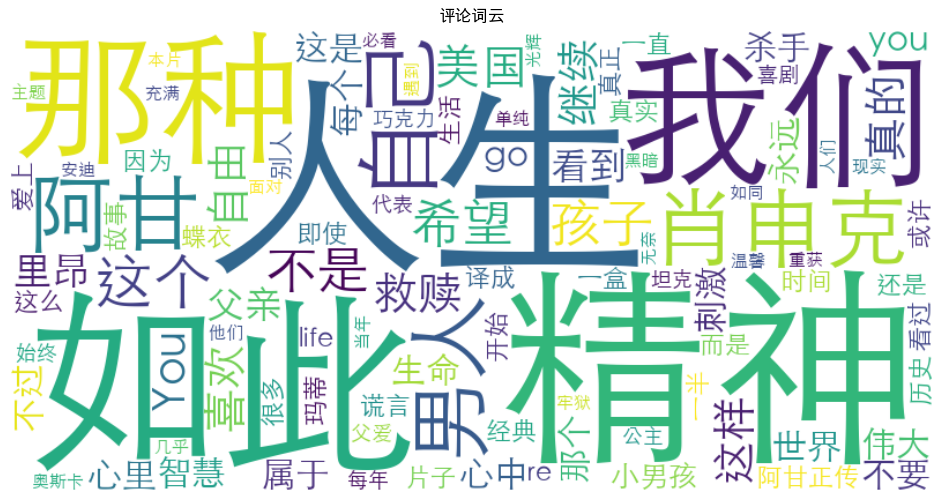

In [15]:
# 词云
all_text = ' '.join(df['content'].astype(str))
words = jieba.cut(all_text)
word_freq = Counter([w for w in words if len(w) > 1 and w not in STOPWORDS])

# 词频统计（Top 20）
top_n = 20
top_words = word_freq.most_common(top_n)
print(f'Top {top_n} 词频:')
print(pd.DataFrame(top_words, columns=['词语', '次数']))

font_path = '/System/Library/Fonts/STHeiti Light.ttc'
if not os.path.exists(font_path):
    font_path = '/System/Library/Fonts/PingFang.ttc'
wc = WordCloud(font_path=font_path, width=800, height=400, background_color='white', max_words=100)
wc.generate_from_frequencies(word_freq)
plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('评论词云')
plt.savefig('output/wordcloud.png', dpi=150)
plt.show()


## 6. 总结
